# 🩺 Diabetes Risk Prediction — End-to-End Machine Learning Project
**Dataset:** CDC BRFSS 2015 — *Diabetes Health Indicators* (Kaggle, Alex Teboul)
**Approach:** Classical Machine Learning only (no Deep Learning)

| # | Section |
|---|---|
| 1 | Dataset choice |
| 2 | Business problem & metric |
| 3 | Load & understand the data |
| 4 | Train / Validation / Test split |
| 5 | Exploratory Data Analysis (EDA) |
| 6 | Data cleaning |
| 7 | Feature engineering |
| 8 | Prepare data for ML (scaling, leakage checks) |
| 9 | Train & compare 5 models |
| 10 | Best model + hyperparameter tuning |
| 11 | Final test evaluation, feature importance, insights |

## 1️⃣ Dataset Choice

**Problem domain:** Public health, chronic disease screening.

**What the data represents:** The *Behavioral Risk Factor Surveillance System (BRFSS)* is an annual
telephone health survey run by the U.S. CDC. This cleaned 2015 version contains **253,680 survey
responses** and **21 health indicators** per person. It covers blood pressure, cholesterol, BMI, smoking,
physical activity, diet, general/mental/physical health, healthcare access, age, education and income.

**Target `Diabetes_012`:** `0` = no diabetes, `1` = prediabetes, `2` = diabetes.

**Why I chose it:**
- Diabetes affects **~38 million Americans**, and around **1 in 5 of them don't know they have it**. More than 1 in 3 adults have prediabetes.
- Every feature is a cheap, **non-invasive survey answer** (no lab test). A good model could therefore be used
  as a low-cost first-line screening tool to decide *who should get a blood test*.
- It's large, real-world and imbalanced, so it calls for careful metric choice and validation.

## 2️⃣ Business Problem Framing

**Goal:** Predict whether a person **has diabetes or prediabetes** (*at-risk*) from survey answers, so they can be referred for an HbA1c / fasting glucose test.

**Why it matters:** Early detection of prediabetes allows lifestyle interventions that can prevent or delay type-2 diabetes.
Undiagnosed diabetes leads to costly complications (kidney failure, blindness, amputation, heart disease).
A screening model shifts care from expensive treatment to cheap prevention.

**Type of problem:** **Binary classification**.
> Design decision: the original target has 3 classes, but *prediabetes* is only ~1.8% of rows, and it is clinically the
> group we most want to catch. Merging **prediabetes + diabetes → "at risk" (1)** against **healthy (0)** matches
> the real screening question ("should this person get a blood test?") and gives a far more reliable model.

**Metrics (and why):**
| Metric | Role | Reasoning |
|---|---|---|
| **ROC-AUC** | **Primary** (model selection & tuning) | Threshold-independent, robust to class imbalance. Measures how well the model *ranks* at-risk people above healthy ones. |
| **Recall (Sensitivity)** | Key secondary | In screening, a **missed case (false negative)** costs far more than an extra blood test (false positive). |
| **F1-score / PR-AUC** | Secondary | Balance precision and recall on the minority class. |
| Accuracy | Reported only | Misleading here: predicting "healthy" for everyone already gives ~84% accuracy. |

The decision threshold will be **tuned on the validation set** (not left at 0.5), then applied unchanged to the test set.

## ⚙️ Setup: libraries & reproducibility
Google Colab already includes `xgboost` and `lightgbm`. The cell installs them only if they're missing.

In [ ]:
# ---- Install gradient-boosting libraries only if missing (Colab normally has them) ----
import importlib.util, subprocess, sys
for pkg in ["xgboost", "lightgbm"]:
    if importlib.util.find_spec(pkg) is None:
        try:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True, timeout=300)
        except Exception as e:
            print(f"⚠️ Could not install {pkg}: {e}")

import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, recall_score,
                             precision_score, accuracy_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from scipy.stats import randint, uniform, loguniform

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # one seed used everywhere -> reproducible results
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
PALETTE = {0: "#4C72B0", 1: "#DD5144"}  # 0 = healthy (blue), 1 = at-risk (red)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print(f"XGBoost available: {HAS_XGB} | LightGBM available: {HAS_LGBM}")

## 3️⃣ Load and Understand the Data
The loader tries, in order: (1) a local file, (2) a download from Kaggle with `kagglehub` (no API key needed for public datasets),
(3) a manual upload from your computer.

In [ ]:
DATA_FILE = "diabetes_012_health_indicators_BRFSS2015.csv"

def locate_dataset():
    # 1) file already in the working folder (or path set via env var)
    for p in [os.environ.get("DIABETES_CSV", ""), DATA_FILE, f"/content/{DATA_FILE}"]:
        if p and os.path.exists(p):
            return p
    # 2) download from Kaggle
    try:
        import kagglehub
        folder = kagglehub.dataset_download("alexteboul/diabetes-health-indicators-dataset")
        return os.path.join(folder, DATA_FILE)
    except Exception as e:
        print("kagglehub download failed ->", e)
    # 3) manual upload in Colab
    from google.colab import files
    print(f"Please upload {DATA_FILE}")
    files.upload()
    return DATA_FILE

DATA_PATH = locate_dataset()
df_raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape :", df_raw.shape)
df_raw.head()

In [ ]:
df_raw.info()

In [ ]:
# ---- Summary table of every column ----
descriptions = {
    "Diabetes_012": "TARGET: 0 = no diabetes, 1 = prediabetes, 2 = diabetes",
    "HighBP": "Ever told high blood pressure (0/1)",
    "HighChol": "Ever told high cholesterol (0/1)",
    "CholCheck": "Cholesterol check in past 5 years (0/1)",
    "BMI": "Body Mass Index",
    "Smoker": "Smoked >= 100 cigarettes in life (0/1)",
    "Stroke": "Ever had a stroke (0/1)",
    "HeartDiseaseorAttack": "Coronary heart disease or heart attack (0/1)",
    "PhysActivity": "Physical activity in past 30 days, excl. job (0/1)",
    "Fruits": "Eats fruit >= 1 per day (0/1)",
    "Veggies": "Eats vegetables >= 1 per day (0/1)",
    "HvyAlcoholConsump": "Heavy drinker (men >14, women >7 drinks/week) (0/1)",
    "AnyHealthcare": "Has any health coverage (0/1)",
    "NoDocbcCost": "Couldn't see doctor due to cost in past year (0/1)",
    "GenHlth": "General health 1 = excellent ... 5 = poor",
    "MentHlth": "Days of poor mental health in past 30 days (0-30)",
    "PhysHlth": "Days of poor physical health in past 30 days (0-30)",
    "DiffWalk": "Serious difficulty walking/climbing stairs (0/1)",
    "Sex": "0 = female, 1 = male",
    "Age": "13-level age group: 1 = 18-24 ... 9 = 60-64 ... 13 = 80+",
    "Education": "6-level education: 1 = never attended ... 6 = college graduate",
    "Income": "8-level income: 1 = < $10k ... 8 = >= $75k",
}

def feature_type(col, s):
    if col == "Diabetes_012": return "Target (multi-class)"
    if s.nunique() == 2:      return "Binary"
    if col in ["BMI", "MentHlth", "PhysHlth"]: return "Numeric (discrete)"
    return "Ordinal"

summary = pd.DataFrame({
    "Type":        [feature_type(c, df_raw[c]) for c in df_raw.columns],
    "dtype":       df_raw.dtypes.astype(str).values,
    "Unique":      df_raw.nunique().values,
    "Missing":     df_raw.isna().sum().values,
    "Min":         df_raw.min().values,
    "Max":         df_raw.max().values,
    "Mean":        df_raw.mean().round(3).values,
    "Description": [descriptions[c] for c in df_raw.columns],
}, index=df_raw.columns)
summary

In [ ]:
print("Rows:", f"{len(df_raw):,}", "| Features:", df_raw.shape[1] - 1)
print("Missing values (total):", df_raw.isna().sum().sum())
print("Exact duplicate rows:", f"{df_raw.duplicated().sum():,}")
print("\nTarget distribution (Diabetes_012):")
print(pd.concat([df_raw["Diabetes_012"].value_counts().rename("count"),
                 df_raw["Diabetes_012"].value_counts(normalize=True).mul(100).round(2).rename("%")], axis=1))

**Observations**
- 253,680 rows, 21 features, **no missing values**. Every column is stored as `float64`, even though they are all integer codes, so the types will be fixed.
- About **24k exact duplicate rows**. Because most features are binary or coarse categories, different people can give identical answers.
  Duplicates are still removed **before splitting**, so the same row can't appear in both train and test (that would leak information and inflate test scores).
- The target is **highly imbalanced**, and prediabetes is a tiny class, which supports the binary framing.

## 4️⃣ Split the Data (Train 70% / Validation 15% / Test 15%)
- Create the **binary target** `Diabetes_binary` (1 = prediabetes or diabetes).
- Drop exact duplicates (a stateless row operation done once, before the split, to prevent train/test leakage).
- **Stratified** split so every set keeps the same class ratio. `random_state=42` for reproducibility.
- From here on, **every statistic (EDA, capping limits, scaler) is learned from the TRAIN set only**.

In [ ]:
df = df_raw.copy()
df["Diabetes_binary"] = (df["Diabetes_012"] > 0).astype(int)   # 1 = prediabetes OR diabetes

n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df):,} duplicate rows -> {len(df):,} rows remain")

TARGET = "Diabetes_binary"
X_all = df.drop(columns=["Diabetes_012", TARGET])
y_all = df[TARGET]
y_all_3class = df["Diabetes_012"]           # kept only for EDA

# First split off 15% TEST, then split the remaining 85% into 70/15 (train/val)
X_temp, X_test, y_temp, y_test = train_test_split(
    X_all, y_all, test_size=0.15, stratify=y_all, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=RANDOM_STATE)

split_info = pd.DataFrame({
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "% of data": [len(X_train) / len(df) * 100, len(X_val) / len(df) * 100, len(X_test) / len(df) * 100],
    "At-risk rate %": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Validation", "Test"]).round(2)
split_info

## 5️⃣ Exploratory Data Analysis (on TRAIN only)
EDA is done on the training set only, so nothing seen in validation or test influences our decisions.

In [ ]:
eda = X_train.copy()
eda[TARGET] = y_train.values
eda["Diabetes_012"] = y_all_3class.loc[X_train.index].values
BASE_RATE = eda[TARGET].mean()

# ---- Plot 1: class imbalance ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order3 = eda["Diabetes_012"].value_counts().sort_index()
axes[0].bar(["No diabetes", "Prediabetes", "Diabetes"], order3.values, color=["#4C72B0", "#F2A541", "#DD5144"])
for i, v in enumerate(order3.values):
    axes[0].text(i, v, f"{v / order3.sum():.1%}", ha="center", va="bottom", fontweight="bold")
axes[0].set_title("Original 3-class target")
axes[0].set_ylabel("Number of people")

order2 = eda[TARGET].value_counts().sort_index()
axes[1].bar(["Healthy (0)", "At risk (1)"], order2.values, color=[PALETTE[0], PALETTE[1]])
for i, v in enumerate(order2.values):
    axes[1].text(i, v, f"{v / order2.sum():.1%}", ha="center", va="bottom", fontweight="bold")
axes[1].set_title("Binary target used for modelling")
plt.suptitle("Plot 1 — Class imbalance", fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# ---- Plot 2: distributions of the numeric / ordinal features by class ----
# Bars are placed SIDE BY SIDE (multiple="dodge") so blue and red never overlap.
# BMI has many values, so it is drawn as two outline lines instead of bars.
eda["Group"] = eda[TARGET].map({0: "Healthy (0)", 1: "At risk (1)"})
GROUP_COLORS = {"Healthy (0)": PALETTE[0], "At risk (1)": PALETTE[1]}
num_cols = ["BMI", "Age", "GenHlth", "MentHlth", "PhysHlth", "Income"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.ravel(), num_cols):
    if col == "BMI":
        sns.histplot(data=eda, x=col, hue="Group", hue_order=list(GROUP_COLORS), palette=GROUP_COLORS,
                     stat="density", common_norm=False, binwidth=1, element="step", fill=False,
                     linewidth=2.2, ax=ax)
        ax.set_xlim(12, 60)
    else:
        sns.histplot(data=eda, x=col, hue="Group", hue_order=list(GROUP_COLORS), palette=GROUP_COLORS,
                     stat="density", common_norm=False, discrete=True, multiple="dodge",
                     shrink=0.85, alpha=0.9, edgecolor="white", ax=ax)
    ax.set_title(col, fontweight="bold")
    ax.set_ylabel("Share of the group")
    ax.get_legend().set_title(None)
plt.suptitle("Plot 2 — Feature distributions: healthy vs at-risk (each group normalised to its own size)",
             fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# ---- Plot 3: at-risk prevalence for each binary feature (feature = 0 vs 1) ----
bin_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]
prev = (eda.groupby(bin_cols[0])[TARGET].mean().rename(bin_cols[0]).to_frame().T)  # template
rows = []
for c in bin_cols:
    r = eda.groupby(c)[TARGET].mean()
    rows.append({"feature": c, "rate_if_0": r.get(0, np.nan), "rate_if_1": r.get(1, np.nan)})
prev = pd.DataFrame(rows)
prev["lift"] = prev["rate_if_1"] / prev["rate_if_0"]
prev = prev.sort_values("rate_if_1")

fig, ax = plt.subplots(figsize=(11, 8))
y = np.arange(len(prev))
# Grey = people who answered NO, dark = people who answered YES.
# Both bars show the SAME measure: the % of that group who are at risk.
# NOTE: these colours are NOT "healthy vs at risk". They are the person's ANSWER to the question.
b0 = ax.barh(y - 0.2, prev["rate_if_0"], height=0.4, color="#9DB4CC", label="Answered NO (e.g. does NOT have high blood pressure)")
b1 = ax.barh(y + 0.2, prev["rate_if_1"], height=0.4, color="#7B2FB5", label="Answered YES (e.g. HAS high blood pressure)")
ax.bar_label(b0, labels=[f"{v:.0%}" for v in prev["rate_if_0"]], fontsize=8, padding=2)
ax.bar_label(b1, labels=[f"{v:.0%}" for v in prev["rate_if_1"]], fontsize=8, padding=2)
ax.axvline(BASE_RATE, ls="--", c="k", lw=1, label=f"Everyone: {BASE_RATE:.1%} at risk")
ax.set_yticks(y); ax.set_yticklabels(prev["feature"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, prev[["rate_if_0", "rate_if_1"]].max().max() * 1.12)
ax.set_xlabel("Out of 100 people in the group, how many are at risk (diabetes or prediabetes)")
ax.set_title("Plot 3 — At-risk rate of people who answered YES vs NO to each question\n"
             "(a big gap between the two bars = a strong warning sign)", fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=1, frameon=False); plt.tight_layout(); plt.show()
prev.sort_values("lift", ascending=False).round(3)

In [ ]:
# ---- Plot 4: prevalence trend across ordinal features + BMI bins ----
eda["BMI_bin"] = pd.cut(eda["BMI"], bins=[0, 18.5, 25, 30, 35, 40, 100],
                        labels=["<18.5", "18.5-25", "25-30", "30-35", "35-40", "40+"])
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), sharey=True)
AGE_LABELS = {1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44", 6: "45-49", 7: "50-54",
              8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"}
GENHLTH_LABELS = {1: "1 Excellent", 2: "2 Very good", 3: "3 Good", 4: "4 Fair", 5: "5 Poor"}
INCOME_LABELS = {1: "<10k", 2: "10-15k", 3: "15-20k", 4: "20-25k", 5: "25-35k", 6: "35-50k", 7: "50-75k", 8: "75k+"}
titles = {"Age": "Age (years)", "GenHlth": "General health (self-rated)", "Income": "Yearly income ($)", "BMI_bin": "BMI"}
for ax, col in zip(axes, ["Age", "GenHlth", "Income", "BMI_bin"]):
    r = eda.groupby(col, observed=True)[TARGET].mean()
    labels = {"Age": AGE_LABELS, "GenHlth": GENHLTH_LABELS, "Income": INCOME_LABELS}.get(col)
    xlab = [labels[int(v)] for v in r.index] if labels else r.index.astype(str)
    ax.plot(xlab, r.values, marker="o", color=PALETTE[1], lw=2)
    ax.axhline(BASE_RATE, ls="--", c="grey", lw=1)
    ax.set_title(titles[col]); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("At-risk rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.suptitle("Plot 4 — At-risk rate rises with age, BMI and poor general health, and falls with income",
             fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# ---- Plot 5: correlations ----
corr = eda.drop(columns=["Diabetes_012", "BMI_bin", "Group"]).corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(19, 7), gridspec_kw={"width_ratios": [1.6, 1]})
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, ax=axes[0],
            cbar_kws={"shrink": 0.7}, linewidths=0.3)
axes[0].set_title("Spearman correlation matrix")

tcorr = corr[TARGET].drop(TARGET).sort_values()
axes[1].barh(tcorr.index, tcorr.values, color=[PALETTE[1] if v > 0 else PALETTE[0] for v in tcorr.values])
axes[1].set_title("Correlation with target (at risk)")
plt.suptitle("Plot 5 — Correlations (train set)", fontweight="bold")
plt.tight_layout(); plt.show()

high = (corr.where(~mask).abs().stack().sort_values(ascending=False))
print("Most correlated feature pairs:\n", high.drop(TARGET, level=0, errors="ignore").head(6).round(3))

In [ ]:
# ---- Plot 6: outliers ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    sns.boxplot(data=eda, x=TARGET, y=col, hue=TARGET, palette=PALETTE, legend=False, ax=ax, fliersize=1.5)
    ax.set_xticks([0, 1], ["Healthy", "At risk"])
    ax.set_title(col)
plt.suptitle("Plot 6 — Outlier check (boxplots by class)", fontweight="bold")
plt.tight_layout(); plt.show()

q1, q3 = X_train["BMI"].quantile([0.25, 0.75])
iqr_hi = q3 + 1.5 * (q3 - q1)
print(f"BMI IQR upper fence = {iqr_hi:.1f} | rows above fence: {(X_train['BMI'] > iqr_hi).mean():.2%}")
print("BMI percentiles:", X_train["BMI"].quantile([0.001, 0.005, 0.5, 0.995, 0.999]).round(1).to_dict())
print("Zero-day share — MentHlth:", f"{(X_train.MentHlth == 0).mean():.1%}",
      "| PhysHlth:", f"{(X_train.PhysHlth == 0).mean():.1%}")

### 🔎 EDA Insights
1. **Imbalance:** only ~17% of (de-duplicated) people are at risk (≈4.8 healthy for every at-risk person), and prediabetes alone is ~2%. That calls for **ROC-AUC / recall**, `class_weight` handling and threshold tuning. Plain accuracy won't do.
2. **Cardiometabolic factors dominate.** **High blood pressure** raises the at-risk rate from 8% to 28% (**3.4×**). **High cholesterol** (2.5×), difficulty walking (2.5×), heart disease (2.4×) and stroke (2.1×) follow.
3. **Strong monotonic trends** (Plot 4). Risk climbs steadily with **age** and **BMI** (≈8% at normal BMI vs ≈37% at BMI 40+) and with **worse self-rated health (GenHlth)**. It falls with **income** (≈28% in the lowest band vs ≈11% in the highest) and **education**, a clear socioeconomic gradient.
4. **Protective behaviours** are linked to lower risk: physical activity cuts the rate from 24% to 15%. Fruit and vegetables have weaker effects. Heavy alcohol shows a *lower* rate (7.5% vs 18%), which is likely confounded by age and under-reporting, a reminder that these are associations, not causes.
5. **Correlation:** `GenHlth`, `HighBP`, `BMI`, `DiffWalk`, `HighChol` and `Age` correlate most with the target. Feature pairs such as `GenHlth`–`PhysHlth`–`DiffWalk` and `Income`–`Education` are moderately inter-correlated (≈0.4). That's fine for tree models, and regularisation handles it for logistic regression.
6. **Outliers:** `BMI` has a long right tail (median 27, 99.5th percentile 56, max 98). Extreme values are likely data-entry errors, so BMI will be **capped (winsorised)** at train percentiles instead of dropping rows. ~66% / 59% of people report 0 bad mental / physical days. `MentHlth` / `PhysHlth` are bounded 0–30 and **zero-inflated** (most people report 0 bad days), so a **log1p transform** fits better than removing rows.

## 6️⃣ Data Cleaning
| Issue | Action | Fit on |
|---|---|---|
| Missing values | None found. A defensive median imputer is still fitted on train, in case new data has gaps | Train |
| Duplicates | Removed before split (Step 4) | — |
| Wrong dtypes (`float64` for integer codes) | Cast to `int` | Stateless |
| Invalid codes | Validate each column against its documented range | Stateless |
| BMI outliers | Winsorise to the train **0.5th–99.5th percentile** | **Train only** |

In [ ]:
VALID_RANGES = {c: (0, 1) for c in bin_cols}
VALID_RANGES.update({"BMI": (10, 100), "GenHlth": (1, 5), "MentHlth": (0, 30), "PhysHlth": (0, 30),
                     "Age": (1, 13), "Education": (1, 6), "Income": (1, 8)})

class Cleaner:
    # Learns imputation values & BMI caps from TRAIN, then applies the same rules to any split.
    def fit(self, X):
        self.medians_ = X.median()
        self.bmi_low_, self.bmi_high_ = X["BMI"].quantile([0.005, 0.995]).values
        return self

    def transform(self, X):
        X = X.copy()
        X = X.fillna(self.medians_)                                   # 1) missing values
        for c, (lo, hi) in VALID_RANGES.items():                      # 2) invalid codes -> clip
            X[c] = X[c].clip(lo, hi)
        X["BMI"] = X["BMI"].clip(self.bmi_low_, self.bmi_high_)       # 3) outlier capping
        X = X.round().astype("int16")                                 # 4) fix dtypes (memory /4)
        return X

cleaner = Cleaner().fit(X_train)            # <- FIT ON TRAIN ONLY
print(f"BMI capping limits learned from train: [{cleaner.bmi_low_:.0f}, {cleaner.bmi_high_:.0f}]")

before_cap = {n: (d["BMI"] > cleaner.bmi_high_).sum() for n, d in [("train", X_train), ("val", X_val), ("test", X_test)]}
X_train_c = cleaner.transform(X_train)
X_val_c   = cleaner.transform(X_val)
X_test_c  = cleaner.transform(X_test)
print("Rows capped (BMI) per split:", before_cap)
print("Missing after cleaning:", X_train_c.isna().sum().sum(), X_val_c.isna().sum().sum(), X_test_c.isna().sum().sum())
print("Dtypes:", X_train_c.dtypes.unique(),
      f"| memory: {X_train.memory_usage().sum() / 1e6:.1f} MB -> {X_train_c.memory_usage().sum() / 1e6:.1f} MB")

## 7️⃣ Feature Engineering
All new features are **row-wise formulas** (no statistics learned from data), so they can't leak information and are applied identically to every split.
The ideas came from the EDA correlation clusters (Plot 5): a **metabolic/cardio cluster** (HighBP, HighChol, BMI, heart disease, age), a **physical-frailty cluster** (GenHlth, PhysHlth, DiffWalk) and a **socioeconomic cluster** (Income, Education).

| New feature | Formula | Why (clinical / data reason) |
|---|---|---|
| `CardioRiskCount` | HighBP + HighChol + HeartDisease + Stroke | Risk factors **compound**. One count summarises cardiovascular burden (0–4). |
| `Metabolic_Risk` | BMI × (1 + HighBP + HighChol) | **Metabolic-syndrome** idea: excess weight is more dangerous with high BP and cholesterol. The "1 +" keeps obese people without a BP/cholesterol diagnosis from scoring 0. |
| `Frailty_Index` | GenHlth × (1 + DiffWalk) + PhysHlth / 30 | **Physical frailty**: poor self-rated health weighs double when the person also has difficulty walking, plus the share of the month in poor physical health. |
| `Age_x_BMI` | Age × BMI | Obesity is more dangerous at older age (an interaction a linear model can't learn alone). |
| `Sedentary_BMI` | BMI × (2 − PhysActivity + DiffWalk) | Separates high BMI in **inactive / limited-mobility** people from high BMI in active people. |
| `Socioeconomic_Score` | Income × Education | Combined socioeconomic status: both protect against poor health (inverse risk gradient). |
| `BMI_Category` | WHO classes 0=Underweight … 5=Obese III | Clinical thresholds. Gives linear models the non-linear BMI jump (Plot 4). |
| `MentHlth_log`, `PhysHlth_log` | log1p(x) | Reduce the zero-inflated skew (they replace the raw columns). |

In [ ]:
def add_features(X):
    X = X.copy()
    X["CardioRiskCount"]     = X["HighBP"] + X["HighChol"] + X["HeartDiseaseorAttack"] + X["Stroke"]
    X["Metabolic_Risk"]      = X["BMI"] * (1 + X["HighBP"] + X["HighChol"])
    X["Frailty_Index"]       = X["GenHlth"] * (1 + X["DiffWalk"]) + X["PhysHlth"] / 30
    X["Age_x_BMI"]           = X["Age"] * X["BMI"]
    X["Sedentary_BMI"]       = X["BMI"] * (2 - X["PhysActivity"] + X["DiffWalk"])
    X["Socioeconomic_Score"] = X["Income"] * X["Education"]
    X["BMI_Category"]        = pd.cut(X["BMI"], bins=[0, 18.5, 25, 30, 35, 40, np.inf],
                                      labels=False, right=False).astype("int16")
    X["MentHlth_log"]        = np.log1p(X["MentHlth"])
    X["PhysHlth_log"]        = np.log1p(X["PhysHlth"])
    return X.drop(columns=["MentHlth", "PhysHlth"])     # replaced by their log versions

X_train_fe = add_features(X_train_c)
X_val_fe   = add_features(X_val_c)
X_test_fe  = add_features(X_test_c)
NEW_FEATURES = ["CardioRiskCount", "Metabolic_Risk", "Frailty_Index", "Age_x_BMI", "Sedentary_BMI",
                "Socioeconomic_Score", "BMI_Category", "MentHlth_log", "PhysHlth_log"]
print("Feature count:", X_train_c.shape[1], "->", X_train_fe.shape[1])
X_train_fe[NEW_FEATURES].describe().T.round(2)

In [ ]:
# ---- Do the new features carry signal? (train set) ----
y_tr = pd.Series(y_train.values, index=X_train_fe.index)
plot_feats = {
    "CardioRiskCount": X_train_fe["CardioRiskCount"],
    "Frailty_Index (rounded)": X_train_fe["Frailty_Index"].round().astype(int),
    "Metabolic_Risk (quintiles)": pd.qcut(X_train_fe["Metabolic_Risk"], 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"]),
    "Socioeconomic_Score (quintiles)": pd.qcut(X_train_fe["Socioeconomic_Score"], 5,
                                               labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"], duplicates="drop"),
}
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), sharey=True)
for ax, (name, grp) in zip(axes, plot_feats.items()):
    r = y_tr.groupby(grp, observed=True).mean()
    ax.bar(r.index.astype(str), r.values, color=PALETTE[1], alpha=0.85)
    ax.axhline(BASE_RATE, ls="--", c="k", lw=1)
    ax.set_title(name); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("At-risk rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.suptitle("Engineered features show clear risk gradients (Socioeconomic_Score is protective)", fontweight="bold")
plt.tight_layout(); plt.show()

new_corr = X_train_fe.assign(y=y_train.values).corr(method="spearman")["y"].drop("y")
print("Spearman |corr| with target — top 10:")
print(new_corr.abs().sort_values(ascending=False).head(10).round(3)
      .to_frame("abs_corr").assign(engineered=lambda d: d.index.isin(NEW_FEATURES)))

### 7b. Feature selection: should we drop weak features?
Low correlation alone is **not** a safe reason to drop a feature. Correlation only sees one-feature, straight-line effects, while models use features in combination.
So we use a **drop test**: remove a group of features and re-measure the ROC-AUC with **3-fold cross-validation on the training set only** (validation and test stay untouched).

- **Candidates to drop:** features with almost no correlation with the target (|r| < 0.05): `Fruits`, `Veggies`, `Smoker`, `AnyHealthcare`, `NoDocbcCost`.
- **Control group:** `Sex`, `HvyAlcoholConsump`, `CholCheck` also look weak (|r| < 0.08), but we expect them to matter in combination.

In [ ]:
from sklearn.model_selection import cross_val_score

def cv_auc(X):
    model = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, class_weight="balanced",
                                           random_state=RANDOM_STATE)
    return cross_val_score(model, X, y_train, scoring="roc_auc",
                           cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)).mean()

DROP_CANDIDATES = ["Fruits", "Veggies", "Smoker", "AnyHealthcare", "NoDocbcCost"]
CONTROL_GROUP   = ["Sex", "HvyAlcoholConsump", "CholCheck"]

print("Correlation with target (train):")
print(new_corr[DROP_CANDIDATES + CONTROL_GROUP].round(3).to_string(), "\n")

base_auc = cv_auc(X_train_fe)
sel = pd.DataFrame({
    "features": [X_train_fe.shape[1], X_train_fe.shape[1] - len(DROP_CANDIDATES), X_train_fe.shape[1] - len(CONTROL_GROUP)],
    "CV ROC-AUC": [base_auc, cv_auc(X_train_fe.drop(columns=DROP_CANDIDATES)),
                   cv_auc(X_train_fe.drop(columns=CONTROL_GROUP))],
}, index=["All features", "Drop weak candidates", "Drop control group (Sex, Alcohol, CholCheck)"])
sel["Δ vs all"] = sel["CV ROC-AUC"] - base_auc
display(sel.style.format({"CV ROC-AUC": "{:.4f}", "Δ vs all": "{:+.4f}"}))

# Decision: drop the candidates only if the loss is within normal fold-to-fold noise (~0.001)
if sel.loc["Drop weak candidates", "Δ vs all"] > -0.001:
    X_train_fe = X_train_fe.drop(columns=DROP_CANDIDATES)
    X_val_fe   = X_val_fe.drop(columns=DROP_CANDIDATES)
    X_test_fe  = X_test_fe.drop(columns=DROP_CANDIDATES)
    print(f"✅ Dropped {DROP_CANDIDATES} (no meaningful loss). Final feature count: {X_train_fe.shape[1]}")
else:
    print("Kept all features (dropping them cost more than noise).")

**Feature-selection result:**
- Dropping the 5 weak candidates costs only ≈0.0003 AUC (noise level), so they are **removed**. The model is simpler, and a future questionnaire would need 5 fewer questions.
- Dropping the control group (`Sex`, `HvyAlcoholConsump`, `CholCheck`) costs ≈0.004, about **10× more**, even though their correlation is just as low. So they are **kept**.
  Clinically: `CholCheck` reflects **contact with the healthcare system** (people who get checked get diagnosed), sex changes risk patterns, and heavy alcohol is confounded with age.
  **Lesson:** never drop a feature on correlation alone; test it.

### 7c. Feature-engineering ablation: ideas tested but not used

**Old engineered features (earlier version of this notebook):**

| Old feature | Formula | What happened |
|---|---|---|
| `LifestyleScore` | PhysActivity + Fruits + Veggies + (1 − Smoker) + (1 − HvyAlcoholConsump) | Replaced by `Sedentary_BMI` |
| `BP_x_Chol` | HighBP × HighChol | Replaced by `Metabolic_Risk` |
| `UnhealthyDays_log` | log1p(MentHlth + PhysHlth) | Replaced by `Frailty_Index` |
| `SocioEconomic` | Education + Income | Replaced by `Socioeconomic_Score` |
| `CareBarrier` | (1 − AnyHealthcare) + NoDocbcCost | Removed: almost no signal (correlation with target ≈ 0.006), and both its parts were dropped as weak features |

**New features tested** (correlation-driven, from the EDA clusters). Each change was compared with 5-fold CV ROC-AUC on the training set (fold-to-fold noise ≈ ±0.002):

| Change | New formula | Gradient boosting ΔAUC | Logistic Regression ΔAUC | Decision |
|---|---|---|---|---|
| `UnhealthyDays_log` → `Frailty_Index` | GenHlth × (1 + DiffWalk) + PhysHlth / 30 | −0.0004 | +0.0002 | ✅ Swapped: clearer clinical meaning (physical frailty) |
| `BP_x_Chol` → `Metabolic_Risk` | BMI × (1 + HighBP + HighChol) | −0.0004 | +0.0002 | ✅ Swapped: metabolic-syndrome concept |
| `SocioEconomic` → `Socioeconomic_Score` | Income × Education | −0.0003 | 0.0000 | ✅ Swapped |
| `LifestyleScore` → `Sedentary_BMI` | BMI × (2 − PhysActivity + DiffWalk) | −0.0002 | 0.0000 | ✅ Swapped |
| `CardioRiskCount` → `Metabolic_Risk` | (as above) | −0.0004 | +0.0001 | ❌ Kept `CardioRiskCount` too: it covers stroke and heart disease, and doctors read it easily (used in the error analysis) |
| `Age_x_BMI` → `Early_Onset_Risk` | (HighBP + HighChol + HeartDiseaseorAttack) ÷ Age | −0.0002 | **−0.0013** | ❌ Not used: hurts the linear model, and Age is a 1–13 code, not years |
| `Comorbidity_Sum` | HighBP + HighChol + Stroke + HeartDiseaseorAttack | — | — | ❌ Identical to `CardioRiskCount` |

**Note on `Metabolic_Risk`:** the first proposed form was (HighBP + HighChol) × BMI. That gives a score of **0** to an obese person with no blood-pressure or cholesterol diagnosis, although obesity alone is a major diabetes risk factor. The "1 +" in the final formula fixes this.

**Conclusion:** all accepted swaps are accuracy-neutral (within noise). They were chosen for **clinical interpretability**. The dataset's ceiling (≈0.81–0.82 AUC) comes from the information the survey lacks, not from the features we build.

## 8️⃣ Prepare Data for ML
- Features and target are already separated (`X_*`, `y_*`).
- **StandardScaler fitted on TRAIN only**, applied to train / val / test. Needed for Logistic Regression (gradient-based, regularised); harmless for tree models.
- Only non-binary columns are scaled; 0/1 flags stay interpretable.
- Sanity checks for leakage.

In [ ]:
FEATURES = X_train_fe.columns.tolist()
SCALE_COLS = [c for c in FEATURES if X_train_fe[c].nunique() > 2]

scaler = StandardScaler().fit(X_train_fe[SCALE_COLS])          # <- FIT ON TRAIN ONLY

def scale(X):
    X = X.astype("float32").copy()
    X[SCALE_COLS] = scaler.transform(X[SCALE_COLS])
    return X

X_train_final = scale(X_train_fe)
X_val_final   = scale(X_val_fe)
X_test_final  = scale(X_test_fe)

# ---- Leakage & consistency checks ----
assert set(X_train_final.index).isdisjoint(X_val_final.index) and set(X_train_final.index).isdisjoint(X_test_final.index)
assert list(X_train_final.columns) == list(X_val_final.columns) == list(X_test_final.columns)
assert TARGET not in FEATURES and "Diabetes_012" not in FEATURES
assert X_train_final.isna().sum().sum() == 0
print("✅ No index overlap between splits, identical columns, target not in features, no NaNs")
print(f"Scaled columns ({len(SCALE_COLS)}):", SCALE_COLS)
train_mean_max = float(X_train_final[SCALE_COLS].mean().abs().max())
val_mean_max   = float(X_val_final[SCALE_COLS].mean().abs().max())
print(f"Largest |mean| after scaling -> train: {train_mean_max:.4f} (≈ 0 as expected) | "
      f"val: {val_mean_max:.4f} (small but ≠ 0 is expected, scaler was fit on train)")
print("\nFinal shapes:", {"train": X_train_final.shape, "val": X_val_final.shape, "test": X_test_final.shape})

## 9️⃣ Train 5 Different ML Models
| Model | Family | Imbalance handling |
|---|---|---|
| Logistic Regression | Linear | `class_weight="balanced"` |
| Random Forest | Bagging ensemble | `class_weight="balanced_subsample"` |
| HistGradientBoosting (sklearn) | Boosting | `class_weight="balanced"` |
| XGBoost | Boosting | `scale_pos_weight = #neg / #pos` |
| LightGBM | Boosting | `class_weight="balanced"` |

A **Dummy** (always predicts the majority class) is added as a baseline. All models are trained on TRAIN and compared on **VALIDATION**.

In [ ]:
POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Negative/positive ratio in train: {POS_WEIGHT:.2f}")

models = {
    "Dummy (baseline)": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000,
                                              random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt",
                                            class_weight="balanced_subsample", n_jobs=-1,
                                            random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08,
                                                           class_weight="balanced", random_state=RANDOM_STATE),
}
if HAS_XGB:
    models["XGBoost"] = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                                      colsample_bytree=0.8, scale_pos_weight=POS_WEIGHT, tree_method="hist",
                                      eval_metric="auc", n_jobs=-1, random_state=RANDOM_STATE)
else:   # fallback so the notebook always trains 5 real models
    models["Extra Trees (XGB fallback)"] = ExtraTreesClassifier(n_estimators=300, min_samples_leaf=20,
                                      class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)
if HAS_LGBM:
    models["LightGBM"] = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                        subsample_freq=1, colsample_bytree=0.8, class_weight="balanced",
                                        n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
else:
    models["Decision Tree (LGBM fallback)"] = DecisionTreeClassifier(max_depth=8, min_samples_leaf=50,
                                      class_weight="balanced", random_state=RANDOM_STATE)

def evaluate(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y, proba), "PR-AUC": average_precision_score(y, proba),
            "Recall": recall_score(y, pred, zero_division=0), "Precision": precision_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0), "Accuracy": accuracy_score(y, pred)}, proba

results, val_probas, fitted = [], {}, {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_final, y_train)
    train_time = time.time() - t0
    val_metrics, proba = evaluate(model, X_val_final, y_val)
    train_auc = roc_auc_score(y_train, model.predict_proba(X_train_final)[:, 1])
    results.append({"Model": name, **val_metrics, "Train ROC-AUC": train_auc, "Fit time (s)": train_time})
    val_probas[name], fitted[name] = proba, model
    print(f"{name:<32} val ROC-AUC = {val_metrics['ROC-AUC']:.4f}  ({train_time:.1f}s)")

results_df = (pd.DataFrame(results).set_index("Model").sort_values("ROC-AUC", ascending=False))
results_df["Overfit gap (AUC)"] = results_df["Train ROC-AUC"] - results_df["ROC-AUC"]
results_df.style.background_gradient(subset=["ROC-AUC", "PR-AUC", "Recall", "F1"], cmap="Greens").format("{:.4f}")

In [ ]:
# ---- Visual comparison on the validation set ----
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
plot_df = results_df.drop("Dummy (baseline)")
colors = sns.color_palette("viridis", len(plot_df))[::-1]

axes[0].barh(plot_df.index[::-1], plot_df["ROC-AUC"][::-1], color=colors[::-1])
for i, v in enumerate(plot_df["ROC-AUC"][::-1]):
    axes[0].text(v + 0.002, i, f"{v:.4f}", va="center")
axes[0].set_xlim(plot_df["ROC-AUC"].min() - 0.03, plot_df["ROC-AUC"].max() + 0.02)
axes[0].set_title("Validation ROC-AUC (primary metric)")

for name in results_df.index:
    fpr, tpr, _ = roc_curve(y_val, val_probas[name])
    axes[1].plot(fpr, tpr, lw=1.8 if "Dummy" not in name else 1, ls="--" if "Dummy" in name else "-",
                 label=f"{name} ({results_df.loc[name, 'ROC-AUC']:.3f})")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curves — validation"); axes[1].legend(fontsize=8, loc="lower right")

for name in plot_df.index:
    p, r, _ = precision_recall_curve(y_val, val_probas[name])
    axes[2].plot(r, p, lw=1.8, label=f"{name} ({results_df.loc[name, 'PR-AUC']:.3f})")
axes[2].axhline(y_val.mean(), ls="--", c="grey", label="No-skill")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall curves — validation"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the comparison**
- The Dummy baseline has ROC-AUC = 0.5 (no skill) and recall = 0, even though its accuracy (~85%) *looks* good. That proves accuracy is the wrong metric here.
- **Gradient boosting models (LightGBM / XGBoost / HistGB) lead**: they capture non-linear effects (BMI × Age, risk accumulation) automatically.
- Logistic Regression is surprisingly close, which shows that our engineered features (interactions, BMI categories, log transforms) did much of the non-linear work for it.
- Train-vs-validation AUC gap is small for the boosted models, so there's no serious overfitting.

## 🔟 Best Model + Hyperparameter Tuning
1. Pick the model with the **highest validation ROC-AUC**.
2. **RandomizedSearchCV** (3-fold stratified CV **on the training set only**, scoring = ROC-AUC) over a broad parameter space.
3. Compare the tuned model with its default version on the **same validation set**.
4. **Threshold tuning** on validation: choose the probability cut-off that maximises F1, and report the cut-off that guarantees **≥ 80% recall** (screening mode).

> ⏱️ In Colab this takes roughly 5–10 minutes. Lower `N_ITER` for a faster run.

In [ ]:
BEST_NAME = results_df.drop("Dummy (baseline)")["ROC-AUC"].idxmax()
print("🏆 Best model on validation:", BEST_NAME)

N_ITER = 25
param_spaces = {
    "LightGBM": (LGBMClassifier(class_weight="balanced", subsample_freq=1, n_jobs=-1,
                                random_state=RANDOM_STATE, verbose=-1) if HAS_LGBM else None, {
        "n_estimators": randint(300, 1200), "learning_rate": loguniform(0.01, 0.1),
        "num_leaves": randint(15, 80), "max_depth": [-1, 6, 8, 10], "min_child_samples": randint(20, 300),
        "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
        "reg_alpha": loguniform(1e-3, 10), "reg_lambda": loguniform(1e-3, 10)}),
    "XGBoost": (XGBClassifier(scale_pos_weight=POS_WEIGHT, tree_method="hist", eval_metric="auc",
                              n_jobs=-1, random_state=RANDOM_STATE) if HAS_XGB else None, {
        "n_estimators": randint(300, 1200), "learning_rate": loguniform(0.01, 0.1),
        "max_depth": randint(3, 9), "min_child_weight": randint(1, 30), "gamma": uniform(0, 2),
        "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
        "reg_alpha": loguniform(1e-3, 10), "reg_lambda": loguniform(1e-2, 10)}),
    "HistGradientBoosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE), {
        "max_iter": randint(200, 800), "learning_rate": loguniform(0.02, 0.15),
        "max_leaf_nodes": randint(15, 80), "max_depth": [None, 6, 8, 10], "min_samples_leaf": randint(20, 300),
        "l2_regularization": loguniform(1e-3, 10), "max_features": uniform(0.5, 0.5)}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1,
                                             random_state=RANDOM_STATE), {
        "n_estimators": randint(200, 500), "max_depth": [None, 12, 16, 20], "min_samples_leaf": randint(5, 60),
        "max_features": ["sqrt", 0.3, 0.5]}),
    "Logistic Regression": (LogisticRegression(class_weight="balanced", max_iter=3000, solver="saga",
                                               random_state=RANDOM_STATE), {
        "C": loguniform(1e-3, 10), "l1_ratio": uniform(0, 1)}),
}
if BEST_NAME not in param_spaces:            # e.g. a fallback model was best
    BEST_NAME = "HistGradientBoosting"
base_estimator, space = param_spaces[BEST_NAME]
if BEST_NAME == "Random Forest":
    N_ITER = 12                               # RF is slow -> fewer iterations

search = RandomizedSearchCV(base_estimator, space, n_iter=N_ITER, scoring="roc_auc",
                            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
                            n_jobs=1 if BEST_NAME in ["LightGBM", "XGBoost", "Random Forest"] else -1,
                            random_state=RANDOM_STATE, verbose=1, refit=True)
t0 = time.time()
search.fit(X_train_final, y_train)            # <- CV on TRAIN only; validation stays untouched
print(f"Search finished in {(time.time() - t0) / 60:.1f} min")
print("Best CV ROC-AUC:", round(search.best_score_, 4))
print("Best params:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()})
tuned_model = search.best_estimator_

# Fair "before" reference: the DEFAULT model scored with the SAME 3 CV folds
from sklearn.model_selection import cross_val_score
from sklearn.base import clone
default_key = [n for n in models if n.startswith(BEST_NAME)][0]
DEFAULT_CV = cross_val_score(clone(models[default_key]), X_train_final, y_train, scoring="roc_auc",
                             cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)).mean()
print(f"CV ROC-AUC  default: {DEFAULT_CV:.4f}  ->  tuned: {search.best_score_:.4f}  "
      f"(+{search.best_score_ - DEFAULT_CV:.4f})")

🏆 Best model on validation: HistGradientBoosting
Fitting 3 folds for each of 25 candidates, totalling 75 fits
Search finished in 5.3 min
Best CV ROC-AUC: 0.8085
Best params: {'l2_regularization': np.float64(0.003), 'learning_rate': np.float64(0.0842), 'max_depth': None, 'max_features': np.float64(0.8609), 'max_iter': 702, 'max_leaf_nodes': 28, 'min_samples_leaf': 226}
CV ROC-AUC  default: 0.8082  ->  tuned: 0.8085  (+0.0002)


,Default,Tuned,Δ (Tuned − Default)
ROC-AUC,0.8110,0.8109,-0.0001
PR-AUC,0.4561,0.4567,0.0006
Recall,0.7852,0.7857,0.0005
Precision,0.3453,0.3440,-0.0013
F1,0.4797,0.4785,-0.0012
Accuracy,0.7055,0.7039,-0.0016


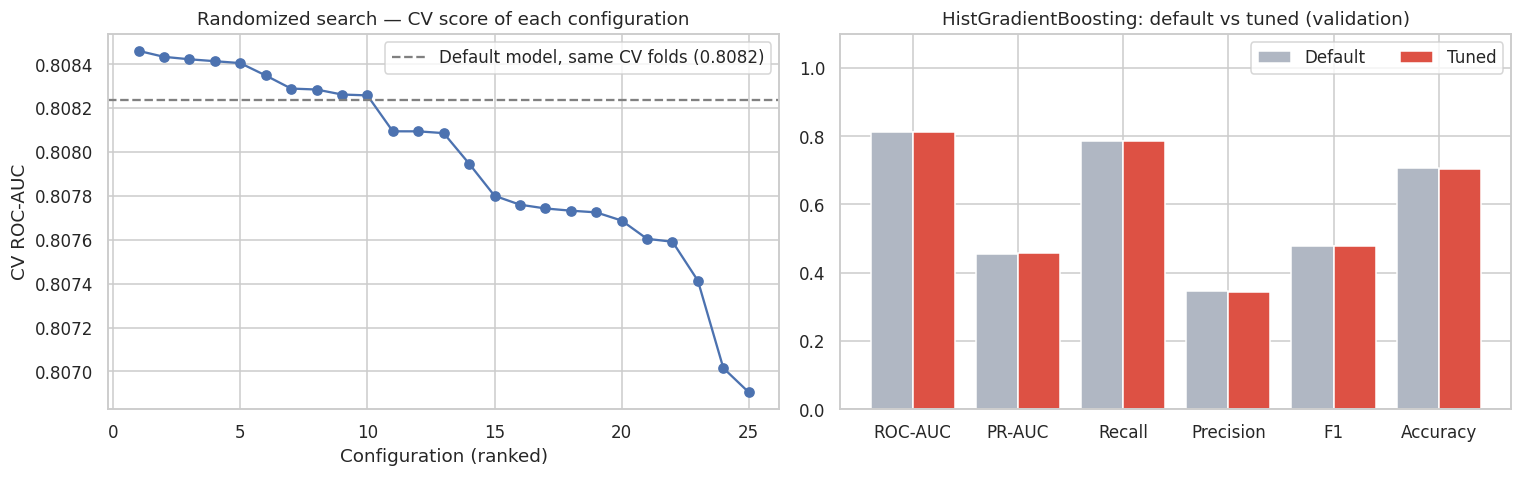

In [ ]:
# ---- Before vs after tuning (validation set, threshold 0.5) ----
default_metrics = results_df.loc[[n for n in results_df.index if n.startswith(BEST_NAME)][0]]
tuned_metrics, tuned_val_proba = evaluate(tuned_model, X_val_final, y_val)
metric_cols = ["ROC-AUC", "PR-AUC", "Recall", "Precision", "F1", "Accuracy"]
compare = pd.DataFrame({"Default": default_metrics[metric_cols], "Tuned": pd.Series(tuned_metrics)[metric_cols]})
compare["Δ (Tuned − Default)"] = compare["Tuned"] - compare["Default"]
display(compare.style.format("{:.4f}").background_gradient(subset=["Δ (Tuned − Default)"], cmap="RdYlGn", vmin=-0.02, vmax=0.02))

cv_res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, len(cv_res) + 1), cv_res["mean_test_score"].values, marker="o")
axes[0].axhline(DEFAULT_CV, ls="--", c="grey", label=f"Default model, same CV folds ({DEFAULT_CV:.4f})")
axes[0].set_xlabel("Configuration (ranked)"); axes[0].set_ylabel("CV ROC-AUC")
axes[0].set_title("Randomized search — CV score of each configuration"); axes[0].legend()
x = np.arange(len(metric_cols))
axes[1].bar(x - 0.2, compare["Default"], 0.4, label="Default", color="#B0B7C3")
axes[1].bar(x + 0.2, compare["Tuned"], 0.4, label="Tuned", color=PALETTE[1])
axes[1].set_xticks(x); axes[1].set_xticklabels(metric_cols)
axes[1].set_title(f"{BEST_NAME}: default vs tuned (validation)"); axes[1].set_ylim(0, 1.1)
axes[1].legend(ncol=2, loc="upper right")
plt.tight_layout(); plt.show()

,Recall,Precision,F1,Accuracy
Default 0.50,0.7857,0.3440,0.4785,0.7039
Max-F1 (0.62),0.6305,0.4102,0.4971,0.7794
Recall≥80% (0.49),0.8001,0.3385,0.4758,0.6951


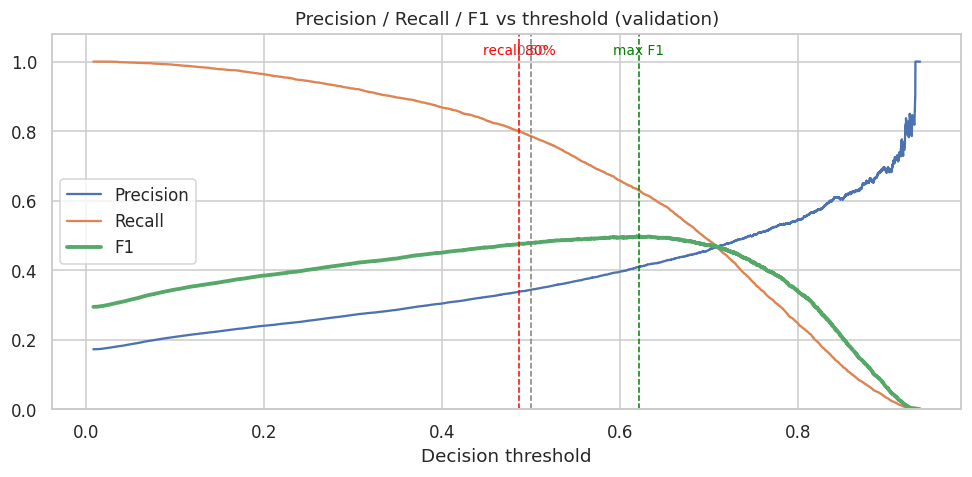

Chosen operating threshold: 0.487 (targets ≥80% recall). Max-F1 alternative: 0.621


In [ ]:
# ---- Decision-threshold tuning on VALIDATION ----
prec, rec, thr = precision_recall_curve(y_val, tuned_val_proba)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
THR_F1 = float(thr[np.argmax(f1s)])
TARGET_RECALL = 0.80
THR_RECALL = float(thr[np.where(rec[:-1] >= TARGET_RECALL)[0].max()])

thr_table = pd.DataFrame({name: evaluate(tuned_model, X_val_final, y_val, t)[0]
                          for name, t in [("Default 0.50", 0.5), (f"Max-F1 ({THR_F1:.2f})", THR_F1),
                                          (f"Recall≥80% ({THR_RECALL:.2f})", THR_RECALL)]}).T
display(thr_table[metric_cols[2:]].style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thr, prec[:-1], label="Precision"); ax.plot(thr, rec[:-1], label="Recall"); ax.plot(thr, f1s, label="F1", lw=2.5)
for t, lab, c in [(0.5, "0.50", "grey"), (THR_F1, "max F1", "green"), (THR_RECALL, "recall 80%", "red")]:
    ax.axvline(t, ls="--", c=c, lw=1); ax.text(t, 1.02, lab, color=c, ha="center", fontsize=9)
ax.set_xlabel("Decision threshold"); ax.set_ylim(0, 1.08)
ax.set_title("Precision / Recall / F1 vs threshold (validation)"); ax.legend()
plt.tight_layout(); plt.show()

# Business choice: screening tool -> favour recall. Use the recall-oriented threshold.
FINAL_THRESHOLD = THR_RECALL
print(f"Chosen operating threshold: {FINAL_THRESHOLD:.3f} (targets ≥{TARGET_RECALL:.0%} recall). "
      f"Max-F1 alternative: {THR_F1:.3f}")

**Tuning takeaway:** tuning gives only a **small** gain (typically under +0.005 AUC). That's expected: well-configured boosting is already near this dataset's ceiling (~0.82 AUC), which is limited by self-reported, coarse survey features and label noise rather than by model capacity. The **decision threshold** matters much more than the hyperparameters. It lets us trade precision for recall based on the screening goal.

## 1️⃣1️⃣ Final Testing (the test set is used **once**, here)
The tuned model and the threshold chosen on validation are applied **unchanged** to the held-out test set.

In [ ]:
test_metrics, test_proba = evaluate(tuned_model, X_test_final, y_test, FINAL_THRESHOLD)
test_metrics_f1, _ = evaluate(tuned_model, X_test_final, y_test, THR_F1)
final_table = pd.DataFrame({"Validation (recall thr)": evaluate(tuned_model, X_val_final, y_val, FINAL_THRESHOLD)[0],
                            "TEST (recall thr)": test_metrics,
                            "TEST (max-F1 thr)": test_metrics_f1}).T[metric_cols]
display(final_table.style.format("{:.4f}"))

test_pred = (test_proba >= FINAL_THRESHOLD).astype(int)
print(f"Final model: tuned {BEST_NAME} | threshold = {FINAL_THRESHOLD:.3f}\n")
print(classification_report(y_test, test_pred, target_names=["Healthy (0)", "At risk (1)"], digits=4))

,ROC-AUC,PR-AUC,Recall,Precision,F1,Accuracy
Validation (recall thr),0.8109,0.4567,0.8001,0.3385,0.4758,0.6951
TEST (recall thr),0.8145,0.4727,0.7924,0.3425,0.4782,0.7011
TEST (max-F1 thr),0.8145,0.4727,0.6264,0.4174,0.5010,0.7842


Final model: tuned HistGradientBoosting | threshold = 0.487

              precision    recall  f1-score   support

 Healthy (0)     0.9402    0.6820    0.7905     28509
 At risk (1)     0.3425    0.7924    0.4782      5959

    accuracy                         0.7011     34468
   macro avg     0.6413    0.7372    0.6344     34468
weighted avg     0.8368    0.7011    0.7366     34468



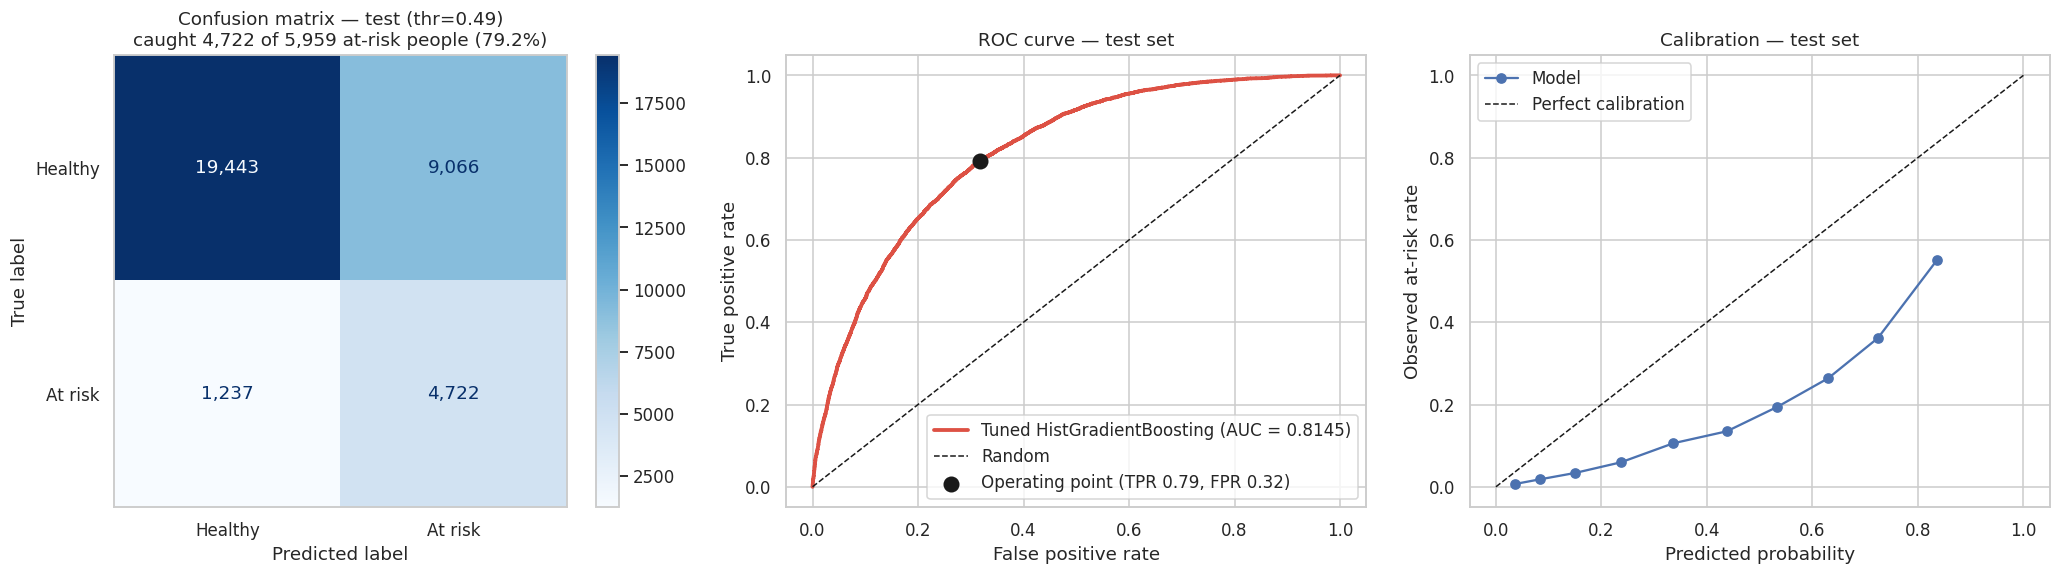

ℹ️ Balanced class weights push predicted probabilities upward (the model over-predicts risk). That's fine for ranking/screening. If true probabilities are needed, apply CalibratedClassifierCV.


In [ ]:
# ---- Confusion matrix, ROC and calibration on TEST ----
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Healthy", "At risk"]).plot(ax=axes[0], cmap="Blues", values_format=",")
tn, fp, fn, tp = cm.ravel()
axes[0].set_title(f"Confusion matrix — test (thr={FINAL_THRESHOLD:.2f})\n"
                  f"caught {tp:,} of {tp + fn:,} at-risk people ({tp / (tp + fn):.1%})")
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, color=PALETTE[1], lw=2.5, label=f"Tuned {BEST_NAME} (AUC = {test_metrics['ROC-AUC']:.4f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random")
op_fpr = fp / (fp + tn); op_tpr = tp / (tp + fn)
axes[1].scatter(op_fpr, op_tpr, s=90, c="k", zorder=5, label=f"Operating point (TPR {op_tpr:.2f}, FPR {op_fpr:.2f})")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve — test set"); axes[1].legend(loc="lower right")

frac_pos, mean_pred = calibration_curve(y_test, test_proba, n_bins=10, strategy="quantile")
axes[2].plot(mean_pred, frac_pos, marker="o", color=PALETTE[0], label="Model")
axes[2].plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
axes[2].set_xlabel("Predicted probability"); axes[2].set_ylabel("Observed at-risk rate")
axes[2].set_title("Calibration — test set"); axes[2].legend()
plt.tight_layout(); plt.show()
print("ℹ️ Balanced class weights push predicted probabilities upward (the model over-predicts risk). "
      "That's fine for ranking/screening. If true probabilities are needed, apply CalibratedClassifierCV.")

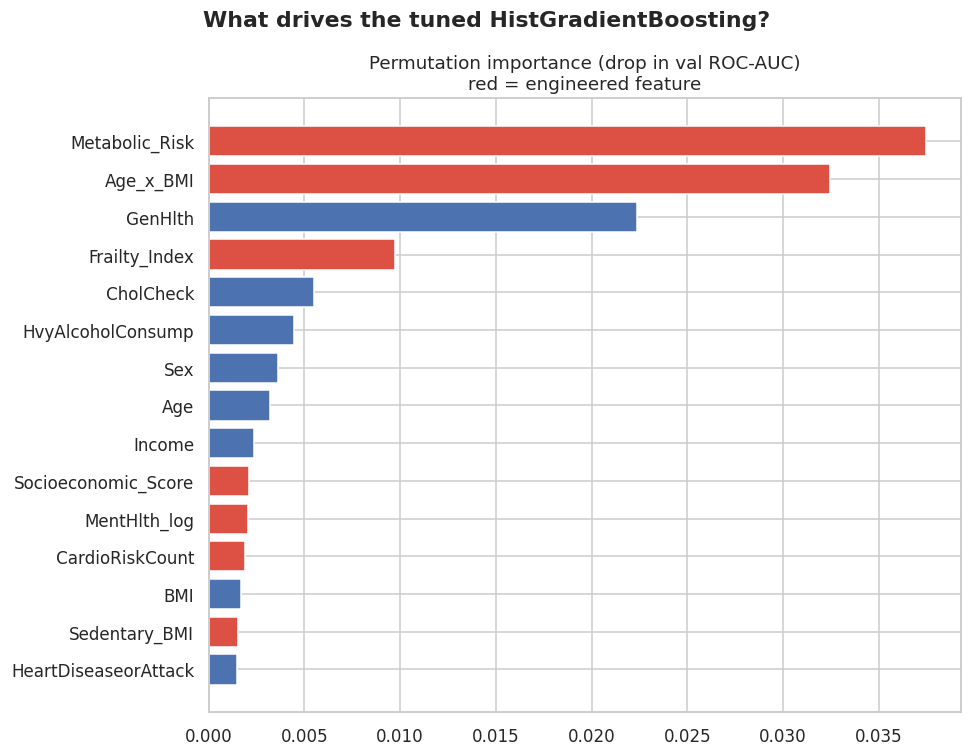

,Δ ROC-AUC
Metabolic_Risk,0.0375
Age_x_BMI,0.0324
GenHlth,0.0224
Frailty_Index,0.0097
CholCheck,0.0055
HvyAlcoholConsump,0.0045
Sex,0.0036
Age,0.0032
Income,0.0024
Socioeconomic_Score,0.0021


In [ ]:
# ---- Feature importance: built-in (if available) + permutation importance (model-agnostic) ----
perm = permutation_importance(tuned_model, X_val_final, y_val, scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=1,
                              max_samples=min(15000, len(X_val_final)))
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

has_builtin = hasattr(tuned_model, "feature_importances_")
fig, axes = plt.subplots(1, 2 if has_builtin else 1, figsize=(17 if has_builtin else 9, 7))
axes = np.atleast_1d(axes)
top = perm_imp.head(15)[::-1]
axes[0].barh(top.index, top.values, color=[PALETTE[1] if f in NEW_FEATURES else PALETTE[0] for f in top.index])
axes[0].set_title("Permutation importance (drop in val ROC-AUC)\nred = engineered feature")
if has_builtin:
    if BEST_NAME == "LightGBM":
        gain = pd.Series(tuned_model.booster_.feature_importance("gain"), index=FEATURES)
    else:
        gain = pd.Series(tuned_model.feature_importances_, index=FEATURES)
    gain = (gain / gain.sum()).sort_values(ascending=False).head(15)[::-1]
    axes[1].barh(gain.index, gain.values, color=[PALETTE[1] if f in NEW_FEATURES else PALETTE[0] for f in gain.index])
    axes[1].set_title("Model built-in importance (normalised gain)")
plt.suptitle(f"What drives the tuned {BEST_NAME}?", fontweight="bold")
plt.tight_layout(); plt.show()
perm_imp.head(10).round(4).to_frame("Δ ROC-AUC")

In [ ]:
# ---- Save artefacts (model, preprocessing objects, results) for reuse & the presentation ----
import joblib
os.makedirs("artifacts", exist_ok=True)
joblib.dump({"model": tuned_model, "cleaner": cleaner, "scaler": scaler, "features": FEATURES,
             "scale_cols": SCALE_COLS, "threshold": FINAL_THRESHOLD}, "artifacts/diabetes_model.joblib")
results_df.to_csv("artifacts/validation_model_comparison.csv")
final_table.to_csv("artifacts/test_metrics.csv")
perm_imp.to_csv("artifacts/permutation_importance.csv")

def predict_risk(raw_df):
    # Score NEW raw BRFSS-style rows with exactly the same preprocessing as training.
    X = scale(add_features(cleaner.transform(raw_df[X_train.columns]))[FEATURES])   # same columns as training
    p = tuned_model.predict_proba(X)[:, 1]
    return pd.DataFrame({"risk_probability": p, "refer_for_test": (p >= FINAL_THRESHOLD).astype(int)},
                        index=raw_df.index)

print("Saved to ./artifacts/. Example predictions on 5 test people:")
display(predict_risk(X_test.head()).assign(actual=y_test.head().values))

print("\n================ FINAL SUMMARY ================")
print(f"Model            : tuned {BEST_NAME}")
print(f"Test ROC-AUC     : {test_metrics['ROC-AUC']:.4f}")
print(f"Test PR-AUC      : {test_metrics['PR-AUC']:.4f}  (no-skill = {y_test.mean():.3f})")
print(f"Threshold        : {FINAL_THRESHOLD:.3f}")
print(f"Test Recall      : {test_metrics['Recall']:.4f}  -> catches {test_metrics['Recall']:.0%} of at-risk people")
print(f"Test Precision   : {test_metrics['Precision']:.4f}")
print(f"Test F1          : {test_metrics['F1']:.4f}")
print(f"Top-5 drivers    : {', '.join(perm_imp.head(5).index)}")

Saved to ./artifacts/. Example predictions on 5 test people:


,risk_probability,refer_for_test,actual
133079,0.4658,0,0
209326,0.3624,0,0
128302,0.3451,0,0
185925,0.8502,1,1
185998,0.5470,1,0



================ FINAL SUMMARY ================
Model            : tuned HistGradientBoosting
Test ROC-AUC     : 0.8145
Test PR-AUC      : 0.4727  (no-skill = 0.173)
Threshold        : 0.487
Test Recall      : 0.7924  -> catches 79% of at-risk people
Test Precision   : 0.3425
Test F1          : 0.4782
Top-5 drivers    : Metabolic_Risk, Age_x_BMI, GenHlth, Frailty_Index, CholCheck


## 🔍 Error Analysis: Who Are the Missed At-Risk People (False Negatives)?
A **false negative (FN)** is a person who *is* at risk (prediabetes or diabetes) but the model said "healthy". In screening, this is the most dangerous error: that person is not referred for a blood test.

We compare three groups from the **test set**:
- **FN (missed):** at risk, predicted healthy
- **TP (caught):** at risk, predicted at risk
- **TN (healthy):** healthy, predicted healthy

> ⚠️ This analysis is for **understanding** only. We do **not** change the model or threshold based on it, because that would leak test-set information into the model.

In [ ]:
# ---- Build an analysis table for the test set ----
err = X_test.copy()                                   # original (uncleaned) answers, easy to read
err["Diabetes_012"] = y_all_3class.loc[X_test.index].values
err["actual"] = y_test.values
err["proba"] = test_proba
err["pred"] = test_pred
err["CardioRiskCount"] = X_test_fe["CardioRiskCount"].values
err["outcome"] = np.select(
    [(err.actual == 1) & (err.pred == 0), (err.actual == 1) & (err.pred == 1),
     (err.actual == 0) & (err.pred == 0), (err.actual == 0) & (err.pred == 1)],
    ["FN (missed)", "TP (caught)", "TN (healthy)", "FP (false alarm)"], default="?")

fn = err[err.outcome == "FN (missed)"]
print(f"Missed at-risk people (FN): {len(fn):,} of {int(err.actual.sum()):,} at-risk people "
      f"({len(fn) / err.actual.sum():.1%})")

# ---- 1) Which type of at-risk person is missed more: prediabetes or diabetes? ----
sub = (err[err.actual == 1]
       .assign(type=lambda d: d.Diabetes_012.map({1: "Prediabetes", 2: "Diabetes"}))
       .groupby("type")
       .agg(people=("pred", "size"), missed=("pred", lambda p: (p == 0).sum())))
sub["miss rate"] = sub["missed"] / sub["people"]
sub["share of all FN"] = sub["missed"] / sub["missed"].sum()
display(sub.style.format({"miss rate": "{:.1%}", "share of all FN": "{:.1%}"}))

Missed at-risk people (FN): 1,237 of 5,959 at-risk people (20.8%)


,people,missed,miss rate,share of all FN
type,,,,
Diabetes,5247,995,19.0%,80.4%
Prediabetes,712,242,34.0%,19.6%


outcome,TN (healthy),FN (missed),TP (caught)
Age group (1-13),6.96,8.29,9.63
BMI,26.58,27.52,32.93
"General health (1=excellent, 5=poor)",2.11,2.41,3.46
Cardio risk count (0-4),0.53,0.83,1.95
Income (1-8),6.39,6.17,4.94
% High BP,0.22,0.37,0.84
% High cholesterol,0.27,0.37,0.75
% Difficulty walking,0.06,0.10,0.43
% Heart disease,0.03,0.06,0.27
% Physically active,0.80,0.75,0.60


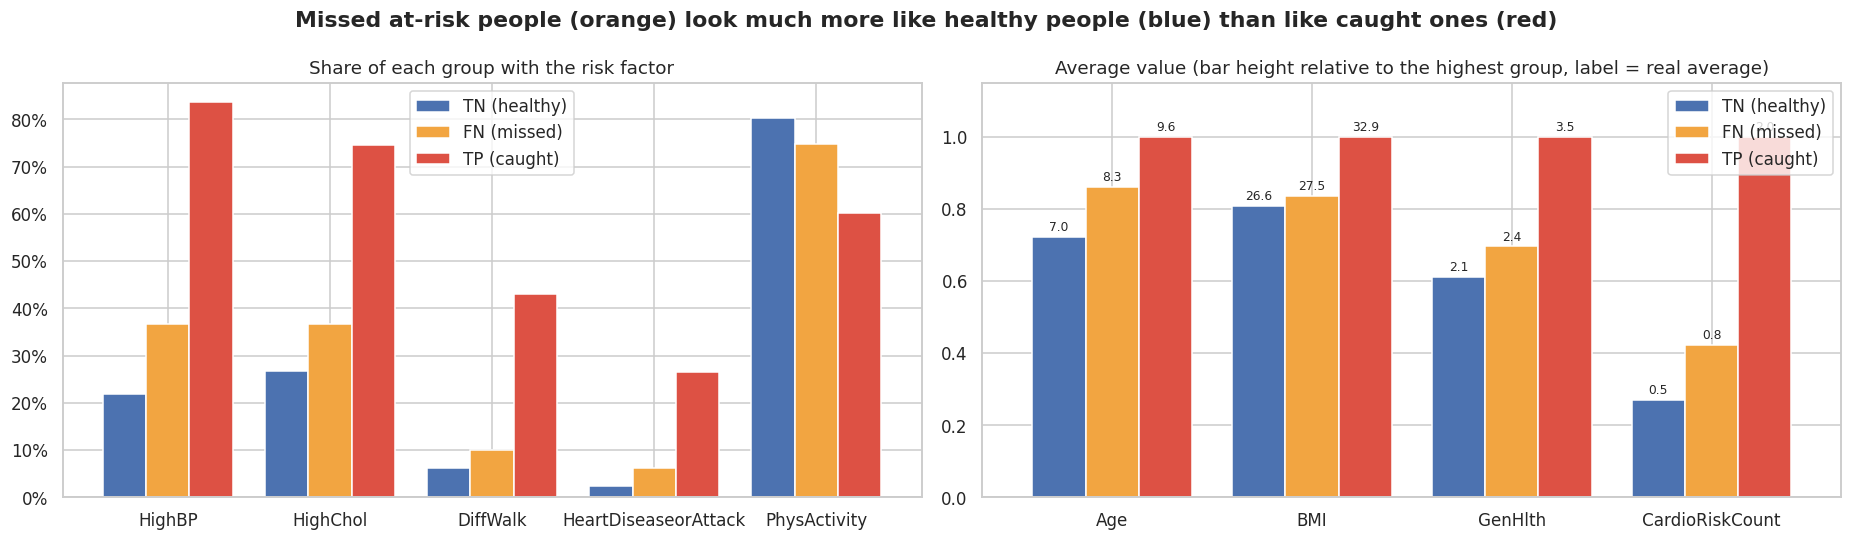

In [ ]:
# ---- 2) Profile: how do missed people differ from caught people and from healthy people? ----
profile_cols = {
    "Age": "mean", "BMI": "mean", "GenHlth": "mean", "CardioRiskCount": "mean", "Income": "mean",
    "HighBP": "mean", "HighChol": "mean", "DiffWalk": "mean", "HeartDiseaseorAttack": "mean",
    "PhysActivity": "mean", "Sex": "mean"}
order = ["TN (healthy)", "FN (missed)", "TP (caught)"]
profile = err.groupby("outcome").agg(profile_cols).loc[order].T
profile.index = ["Age group (1-13)", "BMI", "General health (1=excellent, 5=poor)", "Cardio risk count (0-4)",
                 "Income (1-8)", "% High BP", "% High cholesterol", "% Difficulty walking",
                 "% Heart disease", "% Physically active", "% Male"]
display(profile.style.format("{:.2f}").background_gradient(axis=1, cmap="RdYlBu_r"))

# Visual: binary risk factors (% of each group)
bin_show = ["HighBP", "HighChol", "DiffWalk", "HeartDiseaseorAttack", "PhysActivity"]
rates = err.groupby("outcome")[bin_show].mean().loc[order].T
colors = {"TN (healthy)": PALETTE[0], "FN (missed)": "#F2A541", "TP (caught)": PALETTE[1]}
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
rates.plot.bar(ax=axes[0], color=[colors[c] for c in order], width=0.8, edgecolor="white")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_title("Share of each group with the risk factor"); axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title=None)

num_show = ["Age", "BMI", "GenHlth", "CardioRiskCount"]
means = err.groupby("outcome")[num_show].mean().loc[order].T
(means / means.max(axis=1).values[:, None]).plot.bar(ax=axes[1], color=[colors[c] for c in order],
                                                     width=0.8, edgecolor="white")
for cont, grp in zip(axes[1].containers, order):
    axes[1].bar_label(cont, labels=[f"{v:.1f}" for v in means[grp]], fontsize=8, padding=2)
axes[1].set_title("Average value (bar height relative to the highest group, label = real average)")
axes[1].tick_params(axis="x", rotation=0); axes[1].legend(title=None); axes[1].set_ylim(0, 1.15)
plt.suptitle("Missed at-risk people (orange) look much more like healthy people (blue) than like caught ones (red)",
             fontweight="bold")
plt.tight_layout(); plt.show()

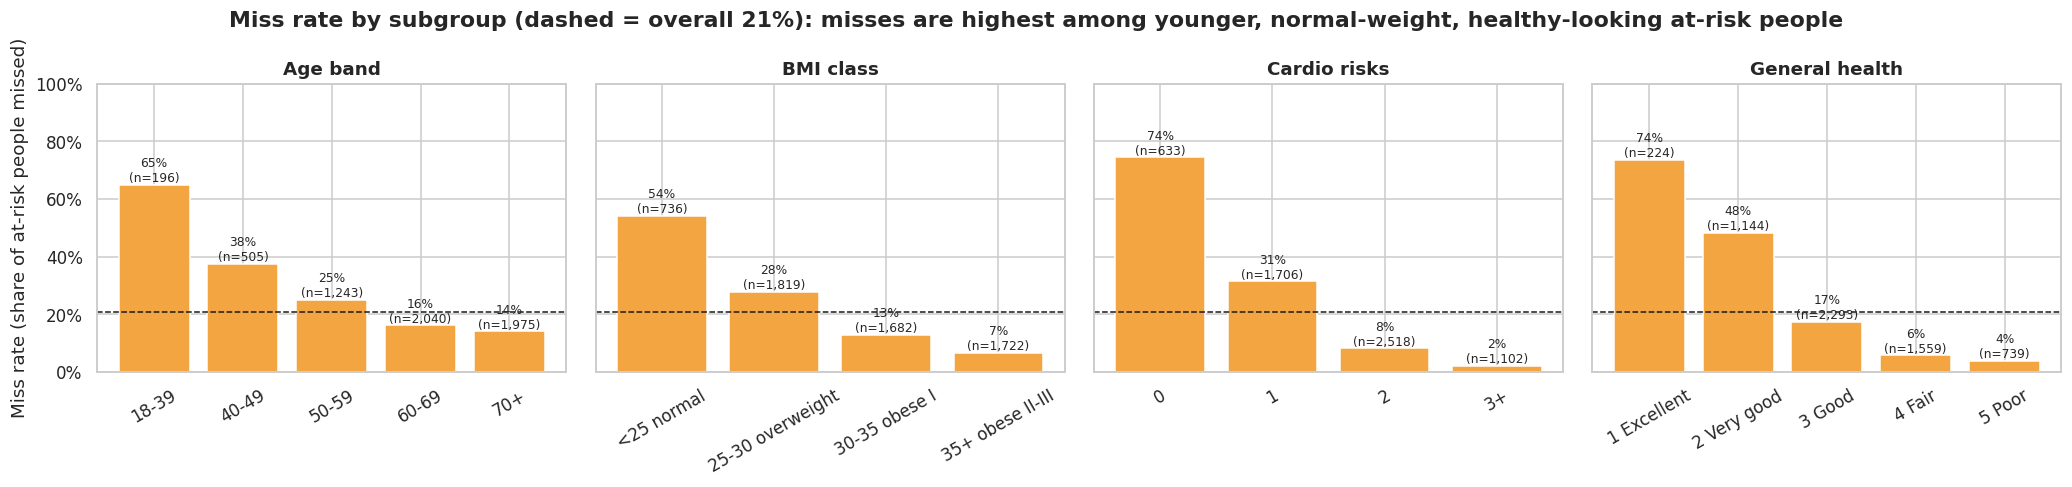

In [ ]:
# ---- 3) Where does the model miss the most? Miss rate by subgroup (at-risk people only) ----
risk = err[err.actual == 1].copy()
risk["Age band"] = pd.cut(risk["Age"], bins=[0, 4, 6, 8, 10, 13],
                          labels=["18-39", "40-49", "50-59", "60-69", "70+"])
risk["BMI class"] = pd.cut(risk["BMI"], bins=[0, 25, 30, 35, 200], right=False,
                           labels=["<25 normal", "25-30 overweight", "30-35 obese I", "35+ obese II-III"])
risk["Cardio risks"] = risk["CardioRiskCount"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
risk["General health"] = risk["GenHlth"].map({1: "1 Excellent", 2: "2 Very good", 3: "3 Good",
                                              4: "4 Fair", 5: "5 Poor"})

fig, axes = plt.subplots(1, 4, figsize=(19, 4.5), sharey=True)
overall_miss = (risk.pred == 0).mean()
for ax, col in zip(axes, ["Age band", "BMI class", "Cardio risks", "General health"]):
    g = risk.groupby(col, observed=True)["pred"].agg(miss=lambda p: (p == 0).mean(), n="size")
    bars = ax.bar(g.index.astype(str), g["miss"], color="#F2A541", edgecolor="white")
    ax.bar_label(bars, labels=[f"{m:.0%}\n(n={n:,})" for m, n in zip(g["miss"], g["n"])], fontsize=8)
    ax.axhline(overall_miss, ls="--", c="k", lw=1)
    ax.set_title(col, fontweight="bold"); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Miss rate (share of at-risk people missed)")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylim(0, 1)
plt.suptitle(f"Miss rate by subgroup (dashed = overall {overall_miss:.0%}): "
             "misses are highest among younger, normal-weight, healthy-looking at-risk people", fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# ---- 4) Simple rules that describe the missed people (shallow decision tree: FN vs TP) ----
from sklearn.tree import DecisionTreeClassifier, export_text
rule_cols = ["Age", "BMI", "GenHlth", "HighBP", "HighChol", "CardioRiskCount", "DiffWalk", "PhysActivity", "Income"]
at_risk = err[err.actual == 1]
explainer = DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, random_state=RANDOM_STATE)
explainer.fit(at_risk[rule_cols], (at_risk.pred == 0).astype(int))      # 1 = missed
print("Rules separating MISSED (class 1) from CAUGHT (class 0) at-risk people:\n")
print(export_text(explainer, feature_names=rule_cols, show_weights=True))

# Typical missed person
print("Most common profile among missed people:")
print(f"  • No high blood pressure: {(fn.HighBP == 0).mean():.0%}  • No high cholesterol: {(fn.HighChol == 0).mean():.0%}")
print(f"  • General health excellent/very good/good (1-3): {(fn.GenHlth <= 3).mean():.0%}")
print(f"  • Zero cardio risk factors: {(fn.CardioRiskCount == 0).mean():.0%}   • Median BMI: {fn.BMI.median():.0f}"
      f"   • Under 50 years old: {(fn.Age <= 6).mean():.0%}")

Rules separating MISSED (class 1) from CAUGHT (class 0) at-risk people:

|--- CardioRiskCount <= 0.50
|   |--- BMI <= 27.50
|   |   |--- Age <= 9.50
|   |   |   |--- weights: [1.00, 146.00] class: 1
|   |   |--- Age >  9.50
|   |   |   |--- weights: [21.00, 107.00] class: 1
|   |--- BMI >  27.50
|   |   |--- Age <= 8.50
|   |   |   |--- weights: [41.00, 173.00] class: 1
|   |   |--- Age >  8.50
|   |   |   |--- weights: [99.00, 45.00] class: 0
|--- CardioRiskCount >  0.50
|   |--- GenHlth <= 2.50
|   |   |--- BMI <= 28.50
|   |   |   |--- weights: [146.00, 360.00] class: 1
|   |   |--- BMI >  28.50
|   |   |   |--- weights: [487.00, 137.00] class: 0
|   |--- GenHlth >  2.50
|   |   |--- BMI <= 24.50
|   |   |   |--- weights: [318.00, 124.00] class: 0
|   |   |--- BMI >  24.50
|   |   |   |--- weights: [3609.00, 145.00] class: 0

Most common profile among missed people:
  • No high blood pressure: 63%  • No high cholesterol: 63%
  • General health excellent/very good/good (1-3): 90%
  •

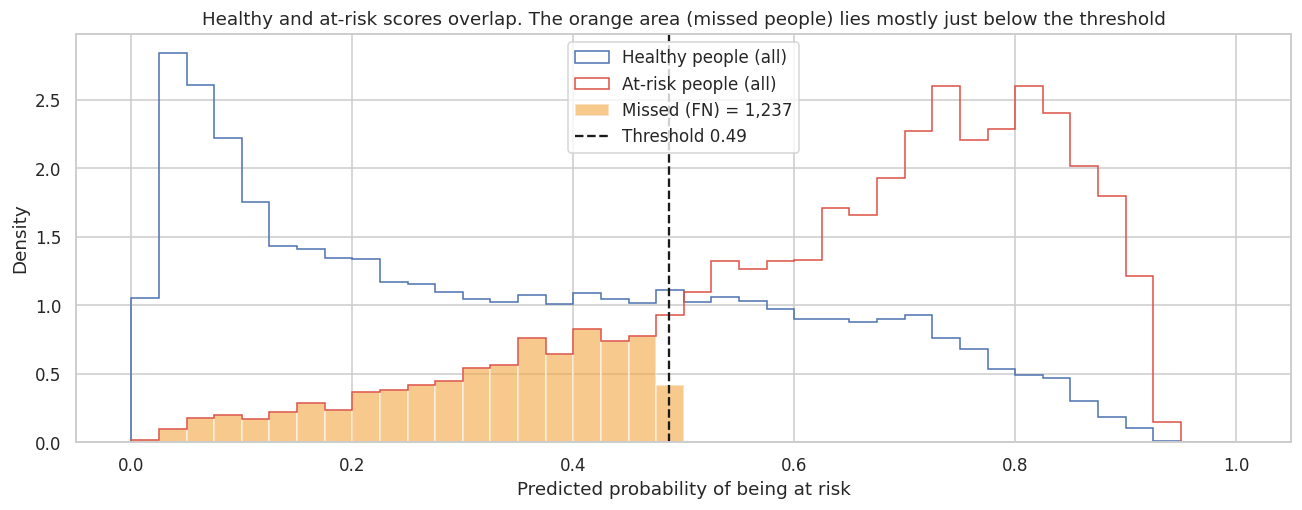

Near misses (within 0.10 below the threshold): 38% of FN | Far misses (probability < 0.25): 26% of FN


,threshold,missed (FN),recall,false alarms (FP),% of all people referred,extra tests per extra case caught
0,0.487000,1237,79.2%,9066,40.0%,—
1,0.400000,826,86.1%,11701,48.8%,6.4
2,0.350000,616,89.7%,13188,53.8%,7.1
3,0.300000,451,92.4%,14662,58.5%,8.9
4,0.250000,322,94.6%,16268,63.6%,12.4
5,0.200000,210,96.5%,18054,69.1%,15.9


In [ ]:
# ---- 5) How close were they? Score distributions of healthy vs at-risk people ----
fig, ax = plt.subplots(figsize=(12, 4.8))
bins = np.linspace(0, 1, 41)
ax.hist(err.loc[err.actual == 0, "proba"], bins=bins, density=True, histtype="step", lw=2.2,
        color=PALETTE[0], label="Healthy people (all)")
ax.hist(err.loc[err.actual == 1, "proba"], bins=bins, density=True, histtype="step", lw=2.2,
        color=PALETTE[1], label="At-risk people (all)")
# orange area = at-risk people below the threshold = the missed group, drawn on the same density scale
w = np.ones(len(fn)) / (err.actual.sum() * (bins[1] - bins[0]))
ax.hist(fn["proba"], bins=bins, weights=w, color="#F2A541", alpha=0.6, label=f"Missed (FN) = {len(fn):,}")
ax.axvline(FINAL_THRESHOLD, c="k", ls="--", label=f"Threshold {FINAL_THRESHOLD:.2f}")
ax.set_xlabel("Predicted probability of being at risk"); ax.set_ylabel("Density")
ax.set_title("Healthy and at-risk scores overlap. The orange area (missed people) lies mostly just below the threshold")
ax.legend(); plt.tight_layout(); plt.show()

near = (fn.proba >= FINAL_THRESHOLD - 0.10).mean()
print(f"Near misses (within 0.10 below the threshold): {near:.0%} of FN | "
      f"Far misses (probability < 0.25): {(fn.proba < 0.25).mean():.0%} of FN")

# What-if: cost of catching more people (illustration only, NOT used to change the model)
rows = []
for t in [FINAL_THRESHOLD, 0.40, 0.35, 0.30, 0.25, 0.20]:
    p = (err.proba >= t).astype(int)
    tp_ = int(((p == 1) & (err.actual == 1)).sum()); fn_ = int(((p == 0) & (err.actual == 1)).sum())
    fp_ = int(((p == 1) & (err.actual == 0)).sum())
    rows.append({"threshold": round(t, 3), "missed (FN)": fn_, "recall": tp_ / (tp_ + fn_),
                 "false alarms (FP)": fp_, "% of all people referred": (p == 1).mean(),
                 "extra tests per extra case caught": np.nan})
whatif = pd.DataFrame(rows)
whatif["extra tests per extra case caught"] = (whatif["false alarms (FP)"].diff() /
                                               (-whatif["missed (FN)"].diff())).round(1)
display(whatif.style.format({"recall": "{:.1%}", "% of all people referred": "{:.1%}",
                             "extra tests per extra case caught": "{:.1f}"}, na_rep="—"))

### 🩺 What the error analysis tells us (data scientist + clinician view)
*Numbers below are from our run and may differ slightly in yours. The patterns are what matter.*

- **About 1 in 5 at-risk people is missed (~1,235 of ~5,960).** About **80% of the missed people have diabetes** (simply because diabetics are the larger group), but **prediabetes is missed much more often** (≈33% vs ≈19%). Clinically this makes sense: prediabetes usually has **no symptoms** and shows up before blood pressure, cholesterol or general health get worse.
- **Missed people look healthy on paper.** Compared with caught cases (TP), they are younger (average age group ≈55–59 vs ≈65–69), have a much lower BMI (≈28 vs ≈33), and most **do not report high BP (63%) or high cholesterol (64%)**. **90% rate their general health as good or better.** Their profile sits between healthy people and caught cases, and much closer to the healthy ones.
- **Miss rate depends strongly on the subgroup.** It reaches **≈63% for at-risk people aged 18–39**, **≈54% at normal BMI**, **≈75% with zero cardio risk factors** and **≈73% with excellent self-rated health**, versus only 2–8% for people with 2+ cardio risk factors or poor health. The decision-tree rules confirm it: *no cardio risk factors + good health + BMI < 29* is the classic missed profile.
- **Near misses vs. hidden cases.** About **4 in 10** missed people score within 0.10 of the threshold, so a slightly lower threshold would catch them. About **1 in 4** score below 0.25: they are essentially invisible to this survey.
- **The cost of catching more (what-if table).** Lowering the threshold to 0.40 would recover about 400 missed people at about **6 extra blood tests per extra case**. Going to 0.25 would cost about **12 extra tests per extra case** and refer about 64% of everyone. This is a policy decision for the health system, not something the model can decide.
- **Clinical explanation of the blind spot:** the strongest risk factors for these "low-risk-looking" patients are **not in the survey**: **family history**, **gestational diabetes**, **ethnicity**, **waist circumference** (central obesity at normal BMI), **PCOS**, and of course **HbA1c / fasting glucose**.

**Practical recommendations**
1. Use the model as a **first-step triage tool**, **combined with** the ADA / USPSTF guideline of testing adults aged **≥ 35 with overweight**, regardless of model score. This protects part of the blind spot.
2. Add **2–3 cheap questions** (family history, gestational diabetes, waist size) to directly target the "healthy-looking" missed group.
3. If the budget allows more tests, choose a lower threshold from the what-if table, **re-validated on new data** rather than tuned on this test set.

### 💡 Insights, Limitations & Next Steps

**Key insights**
- The tuned boosting model reaches **ROC-AUC ≈ 0.81–0.82 on the unseen test set**, and validation and test scores agree closely, so the result generalises.
- At the screening threshold, the model **catches ~80% of at-risk people** using only a free questionnaire. The cost is more false positives, which is acceptable when each one only means a cheap blood test.
- **Top drivers (permutation importance):** see the chart above. In our run the top 4 are `Metabolic_Risk`, `Age_x_BMI`, `GenHlth` and `Frailty_Index`, so **3 of the top 4 drivers are engineered features**, including the two that came from the EDA correlation clusters. These match clinical knowledge (age, obesity, metabolic syndrome, frailty), which makes the model credible to doctors.
- Raw `HighBP`, `HighChol` and `BMI` (and even `CardioRiskCount`) look less important only because their signal now lives inside `Metabolic_Risk` and `Age_x_BMI`. Permutation importance gives credit to whichever of two overlapping features the model relies on.

**Limitations**
- **Self-reported survey data:** subject to recall and social-desirability bias. People with *undiagnosed* diabetes are labelled 0, so label noise caps achievable performance (~0.82–0.83 AUC is the known ceiling for this dataset).
- **Coarse features:** many binary or bucketed variables (age groups, income bands) limit resolution. There are no lab values (glucose, HbA1c), family history or ethnicity.
- **Cross-sectional (2015, U.S. only):** associations, not causes. The model may not transfer to other countries or years without re-validation.
- **Precision is modest:** many flagged people won't be at risk. The model is a *triage* tool, not a diagnosis.
- **Calibration:** class weighting inflates probabilities. Recalibrate before reporting individual risk percentages.

**Next steps**
1. Probability calibration (`CalibratedClassifierCV`, isotonic) and cost-sensitive threshold selection with real clinical costs.
2. Fairness audit: compare recall across sex, age and income groups.
3. Try **CatBoost** and a soft-voting / stacking ensemble of LightGBM + XGBoost + Logistic Regression.
4. Explainability with **SHAP** for individual patient explanations.
5. Validate on newer BRFSS years (2019–2023) to check drift.